![Banner](../../../../Images/Banner/05_geostat/07_simulation.png)

# Simulated Annealing Simulation (`sasim`)

**Dataset:** Jura soil survey, Swiss Jura (`Data/00_shared/data_geostatistics/jura_data.csv`, 359 samples) + prediction grid (`Data/00_shared/data_geostatistics/jura_grid.csv`, 5,957 nodes on a 50 m lattice; every second row and column, a 100 m lattice of 1,540 nodes, is used for annealing)

**Targets:** nickel (`Ni`, mg/kg) as a continuous variable, rock type (`Rock`, five geological units) as a categorical variable, and a kriged chromium map as a secondary variable

**Library:** `geolattice.geostatistics`: `SimulatedAnnealing`, `sasim` (module `geolattice.geostatistics.simulation.annealing`)

**Before this notebook:** [Introduction to geostatistical simulation](05_07_00_introduction_geostatistical_sumulations.ipynb) and [sequential Gaussian simulation](05_07_01_sgsim.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Simulation as optimization](#simulation-as-optimization)
    - 2.2 [The objective function](#the-objective-function)
    - 2.3 [Swaps: the histogram for free](#swaps-the-histogram-for-free)
    - 2.4 [The Metropolis rule and the annealing schedule](#the-metropolis-rule-and-the-annealing-schedule)
    - 2.5 [Incremental updates](#incremental-updates)
    - 2.6 [Hard data, the lattice, and what annealing does not guarantee](#hard-data-the-lattice-and-what-annealing-does-not-guarantee)
    - 2.7 [The algorithm](#the-algorithm)
3. [Python Setup](#python-setup)
4. [Jura Data and the Annealing Lattice](#jura-data-and-the-annealing-lattice)
5. [Target Variograms](#target-variograms)
6. [A First Run with `SimulatedAnnealing`](#a-first-run-with-simulatedannealing)
7. [Variogram Reproduction by Direction](#variogram-reproduction-by-direction)
8. [The Annealing Schedule](#the-annealing-schedule)
9. [Conditioning and Local Accuracy: Annealing vs SGS](#conditioning-and-local-accuracy-annealing-vs-sgs)
10. [A Secondary Variable: the Correlation Component](#a-secondary-variable-the-correlation-component)
11. [Categorical Annealing: Rock Type](#categorical-annealing-rock-type)
12. [Visualization of Spatial Uncertainty](#visualization-of-spatial-uncertainty)
    - 12.1 [Animated display of realizations](#animated-display-of-realizations)
    - 12.2 [Conditional quantile maps (q10, median, q90)](#conditional-quantile-maps-q10-median-q90)
13. [Run Time](#run-time)
14. [Summary and Conclusions](#summary-and-conclusions)
    - 14.1 [Choosing the options](#choosing-the-options)
15. [References](#references)

***
## Overview

Sequential, spectral and turning-band simulators all *construct* a realization from a random-function model. **Simulated annealing** works the other way round. It starts from any image that already has the right histogram, and *rearranges* it until the image matches a list of target statistics. The targets can be the variogram, indicator variograms for each class, and the correlation with a secondary variable. The rearrangement is a stochastic optimization borrowed from statistical physics (Kirkpatrick et al., 1983), adapted to geostatistics by Deutsch (1992) and Deutsch & Journel (GSLIB `sasim` / `anneal`).

Its strengths and weaknesses follow from that design:

| | Simulated annealing |
|---|---|
| **Histogram** | reproduced **exactly**: the image is a permutation of the target values |
| **Variogram(s)** | reproduced as closely as the optimization allows, at the lags and directions in the objective |
| **Categorical proportions** | exact (contrast with [SIS](05_07_04_sicosim.ipynb)) |
| **Several criteria at once** | yes: any statistic that can be written as an objective component |
| **Data conditioning** | hard data are fixed, but their influence on nearby nodes comes only through the variogram pairs |
| **Uncertainty model** | none explicit: the spread between realizations depends on the objective and the schedule, not on a random-function model |
| **Cost** | many swaps (hundreds per node); CPU only in GeoLattice |

The objects:

| Object | What it does |
|---|---|
| `SimulatedAnnealing` | `fit(grid, df, ..., secondary=None)` sets up the lattice, hard data, targets and secondary. `simulate(nsim, seed)` returns realizations at the grid nodes; `simulate_lattice` returns the full lattice. `history_`, `objective_` and `n_swaps_` record the optimization, and `experimental_variogram` / `target_variogram` evaluate an image at the objective lags. |
| `sasim` | One-call wrapper. |

On the Jura data the notebook:

* simulates nickel with a variogram objective, and checks exact histogram reproduction, variogram reproduction by direction, the effect of the annealing schedule, and local accuracy at 100 held-out sites against SGS;
* adds a correlation component with a kriged chromium map;
* simulates rock type with indicator variograms, with exact proportions, checked against the geology map.

***
## Theory

### Simulation as optimization

A realization is any image $\{z(\mathbf{u}_j)\}_{j=1}^{N}$ on the lattice. Annealing defines an **objective function** $O \ge 0$ that is 0 when the image has every target statistic, and searches for images with small $O$. Different random starting images and random swap sequences lead to different low-$O$ images: the realizations. There is no explicit random-function model. The set of realizations is "all images that match the targets well", sampled by a randomized search. Two consequences follow:

* anything that can be measured on an image can be a target;
* the uncertainty between realizations is not calibrated by a probability model.

### The objective function

The **variogram component** compares the image's experimental variogram with the target model at a set of lag vectors. GeoLattice uses $K$ = `n_lags` multiples of each direction $\mathbf{d}$ in `directions` (default: the two axes and both diagonals, in cells):

$$
O_\gamma = \sum_{\mathbf{d}} \sum_{k=1}^{K} w_k\, \frac{\bigl[\hat\gamma(k\mathbf{d}) - \gamma(k\mathbf{d})\bigr]^2}{\gamma(k\mathbf{d})^2},
\qquad w_k \propto \frac{1}{k},
\qquad
\hat\gamma(\mathbf{h}) = \frac{1}{2N(\mathbf{h})} \sum_{N(\mathbf{h})} \bigl[z(\mathbf{u}) - z(\mathbf{u} + \mathbf{h})\bigr]^2 .
$$

Dividing by $\gamma^2$ makes every lag count in *relative* terms, so short lags (small $\gamma$) are matched as carefully as long ones. The weights $1/k$ give extra emphasis to the short lags, which control the look of the image. $\gamma$ is the model `vario` in original units, `[azimuth, nugget, major_range, minor_range, sill, vtype]`, evaluated at the lag vectors in coordinate units.

For a **categorical** variable with classes $s_1, \dots, s_C$, the **indicator component** is the same sum over each class's indicator variogram $\gamma_I(\mathbf{h}; s_c)$ from `indicator_varios`.

With an exhaustive secondary $y(\mathbf{u})$, the **correlation component** is

$$
O_\rho = \bigl(\hat\rho_{zy} - \rho^{\text{target}}\bigr)^2 ,
$$

with $\hat\rho_{zy}$ the correlation of the image with the secondary over the lattice, and $\rho^{\text{target}}$ = `target_correlation` (default: the correlation of the data with the secondary).

Components live on different scales. As in GSLIB `sasim`, each is divided by the **mean absolute change** it undergoes over a set of random swaps of the starting image, $\overline{|\Delta O_c|}$:

$$
O = \sum_c \frac{\omega_c}{\overline{|\Delta O_c|}}\, O_c ,
$$

so the user weights $\omega_c$ (`component_weights`, e.g. `{"variogram": 1, "correlation": 5}`) are *relative importances*.

### Swaps: the histogram for free

The starting image puts the **stratified quantiles** of the target histogram (`target_values`, by default the data) at the free nodes in random order:

$$
z_j = F^{-1}\!\left(\frac{j - 1/2}{N_{\text{free}}}\right), \qquad j = 1, \dots, N_{\text{free}}, \quad \text{randomly permuted.}
$$

Every perturbation is a **swap** of the values at two free nodes. A swap never changes the set of values, so **the histogram is reproduced exactly**, in every realization, at every step. For categorical variables this means the **class proportions are exact**, which sequential indicator simulation cannot guarantee.

### The Metropolis rule and the annealing schedule

A swap that changes the objective from $O$ to $O'$ is accepted with probability

$$
P(\text{accept}) = \begin{cases} 1 & O' \le O \\ \exp\bigl(-(O' - O)/t\bigr) & O' > O, \end{cases}
$$

the Metropolis rule at temperature $t$. Accepting some bad swaps early lets the search escape poor local minima. As $t$ falls, the search becomes greedy. The **schedule**:

| Parameter | Meaning | Default |
|---|---|---|
| `t0` | initial temperature, in units of the mean objective increase of a random swap (1 accepts a typical bad swap with probability $e^{-1} \approx 0.37$) | 1.0 |
| `reduction` | $t \leftarrow \lambda\, t$ after each temperature step | 0.1 |
| `k_accept` | accepted swaps per temperature | $5\,N_{\text{free}}$ |
| `k_max` | attempted swaps per temperature | $50\,N_{\text{free}}$ |
| `max_swaps` | total budget | $500\,N_{\text{free}}$ |
| `tol` | stop when $O \le \text{tol} \cdot O_{\text{init}}$ | $10^{-3}$ |
| `n_stop` | stop after this many temperatures with no accepted swap | 3 |

A fast schedule (small `t0`, small `reduction`) is close to a greedy descent: quick, but it can freeze in a poor arrangement. A slow schedule explores more. In GSLIB practice a fairly fast schedule works for variogram objectives because the objective landscape is benign (Deutsch & Journel, 1998).

### Incremental updates

Recomputing the variogram after each swap would cost $O(N)$ per lag. A swap only changes the pairs that involve the two swapped nodes, so GeoLattice updates the per-lag sums of squared differences from those pairs alone: $O(L)$ per swap, with $L$ the number of lag vectors. The lattice is padded with missing values so that pairs leaving the lattice are simply skipped. The correlation component is updated in $O(1)$ from the change in $\sum z y$.

### Hard data, the lattice, and what annealing does not guarantee

* **Lattice.** Annealing works on a regular lattice. `fit` infers it from the grid (or `spacing`), and it spans the **bounding box** of the grid and the data. Lattice nodes outside an irregular study area are simulated too, and they enter the objective, but `simulate` returns only the requested grid nodes.
* **Hard data** are moved to their nearest lattice node. Several data at one node are averaged (continuous) or take their most frequent class (categorical). Those nodes are never swapped, so the data are honoured exactly at their nodes.
* **Conditioning is weak.** A datum influences its neighbours only through the variogram pairs it belongs to. One pair among thousands at each lag carries almost no weight in $O$, so nothing forces the nodes next to a high datum to be high. Annealed realizations can show **discontinuities around the data**, and their spread near the data can be too large. Sequential methods condition through kriging and do not have this problem. Section 9 measures it.
* **No probability model.** The spread between realizations reflects the many images that fit the targets, not a posterior distribution. It is not guaranteed to be calibrated.

### The algorithm

For each realization:

1. Place the hard data on the lattice; fill the free nodes with stratified quantiles of the target histogram in random order.
2. Compute the objective components, their scaling from random swaps, and the initial temperature.
3. Repeat until $O \le \text{tol} \cdot O_{\text{init}}$, the swap budget is spent, or `n_stop` temperatures pass with no accepted swap:
    1. at temperature $t$, propose swaps of two random free nodes, update $O$ incrementally, and accept by the Metropolis rule, until `k_accept` acceptances or `k_max` attempts;
    2. record $O / O_{\text{init}}$ in `history_` and set $t \leftarrow$ `reduction` $\cdot\, t$.
4. Return the image at the grid nodes.

***
## Python Setup

`SimulatedAnnealing` runs on the CPU only. Each swap is a small NumPy update, and realizations run one after another. The cost grows with the number of lattice nodes, because the default swap budget and the swaps per temperature are proportional to it. The notebook therefore anneals on a 100 m lattice; Section 13 times the 50 m lattice too. Plain SGS (`sgsim_gpu`) is used for comparison, on the GPU when one is available.

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import OrdinaryKriging, SimulatedAnnealing, Variogram, sasim, sgsim_gpu
from geolattice.geostatistics.gslib.nscore import nscore_forward
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

print("pygstat version:", pygstat.__version__)
USE_GPU = cupy_gpu_usable()
print("SimulatedAnnealing : CPU (NumPy)")
print(f"sgsim_gpu baseline : {'GPU (CuPy)' if USE_GPU else 'CPU'}")

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")

pygstat version: 0.3.44
SimulatedAnnealing : CPU (NumPy)
sgsim_gpu baseline : GPU (CuPy)


***
## Jura Data and the Annealing Lattice

The Jura data (Atteia et al., 1994; Goovaerts, 1997) are 359 topsoil samples from a 14.5 km² area of the Swiss Jura. `jura_grid.csv` holds 5,957 nodes on a 50 m lattice, with the mapped geology. Coordinates are in kilometres. Every second row and column gives a **100 m grid** of 1,540 nodes; its lattice (the bounding box) has 49 × 59 = 2,891 nodes.

As in the earlier notebooks, 100 samples are held out at random as a validation set, and the other 259 are the conditioning data.

In [2]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
df_all = pd.read_csv(DATA + "jura_data.csv", index_col=0)
grid_df = pd.read_csv(DATA + "jura_grid.csv", index_col=0)
grid50 = grid_df[["Xloc", "Yloc"]].to_numpy(dtype=float)
i50 = np.rint((grid50[:, 0] - grid50[:, 0].min()) / 0.05).astype(int)
j50 = np.rint((grid50[:, 1] - grid50[:, 1].min()) / 0.05).astype(int)
keep = (i50 % 2 == 0) & (j50 % 2 == 0)
grid = grid50[keep]                                   # 100 m annealing grid
ROCKS = {1: "Argovian", 2: "Kimmeridgian", 3: "Sequanian", 4: "Portlandian", 5: "Quaternary"}
grid_rock = grid_df["Rock"].map({v: k for k, v in ROCKS.items()}).to_numpy()[keep]

CELL = 0.10
ix = np.rint((grid[:, 0] - grid[:, 0].min()) / CELL).astype(int)
iy = np.rint((grid[:, 1] - grid[:, 1].min()) / CELL).astype(int)
EXTENT = [grid[:, 0].min() - CELL / 2, grid[:, 0].max() + CELL / 2,
          grid[:, 1].min() - CELL / 2, grid[:, 1].max() + CELL / 2]
ROCK_CMAP = ListedColormap(["#4daf4a", "#377eb8", "#ff7f00", "#984ea3", "#e7d84d"])


def to_image(values):
    img = np.full((iy.max() + 1, ix.max() + 1), np.nan)
    img[iy, ix] = values
    return img


def show_map(ax, values, title, cmap="viridis", vmin=None, vmax=None, label="Ni (mg/kg)", points=None):
    im = ax.imshow(to_image(values), origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax,
                   interpolation="nearest")
    if points is not None:
        ax.scatter(points[:, 0], points[:, 1], s=6, facecolors="none", edgecolors="k", linewidths=0.4)
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.04)
    return im


def show_rock(ax, codes, title):
    im = ax.imshow(to_image(codes), origin="lower", extent=EXTENT, cmap=ROCK_CMAP, vmin=0.5, vmax=5.5,
                   interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.set_aspect("equal")
    cb = plt.colorbar(im, ax=ax, ticks=list(ROCKS), fraction=0.046, pad=0.04)
    cb.ax.set_yticklabels(list(ROCKS.values()))


rng_split = np.random.default_rng(359)
test_idx = np.sort(rng_split.choice(len(df_all), size=100, replace=False))
is_test = np.zeros(len(df_all), bool)
is_test[test_idx] = True
df = df_all[~is_test].reset_index(drop=True)
test = df_all[is_test].reset_index(drop=True)
xy, xy_test = df[["Xloc", "Yloc"]].to_numpy(float), test[["Xloc", "Yloc"]].to_numpy(float)
ni = df["Ni"].to_numpy(float)
print(f"100 m grid: {len(grid)} nodes;  conditioning data: {len(df)};  validation sites: {len(test)}")
print(f"Ni (259): mean {ni.mean():.2f}, sd {ni.std():.2f}, skewness {pd.Series(ni).skew():.2f}")

100 m grid: 1540 nodes;  conditioning data: 259;  validation sites: 100
Ni (259): mean 20.14, sd 7.73, skewness -0.06


***
## Target Variograms

Annealing matches a variogram in **original units**, so the target is the variogram of nickel in mg/kg, with the sill equal to its variance. SGS, used for comparison, needs the variogram of the normal scores. Both are spherical models fitted by weighted least squares with the sill fixed.

vario_ni (mg/kg, annealing target): [0.0, np.float64(10.057), np.float64(0.94), np.float64(0.94), np.float64(59.796), 'spherical']
vario_ns (normal scores, SGS)      : [0.0, np.float64(0.216), np.float64(0.944), np.float64(0.944), 1.0, 'spherical']


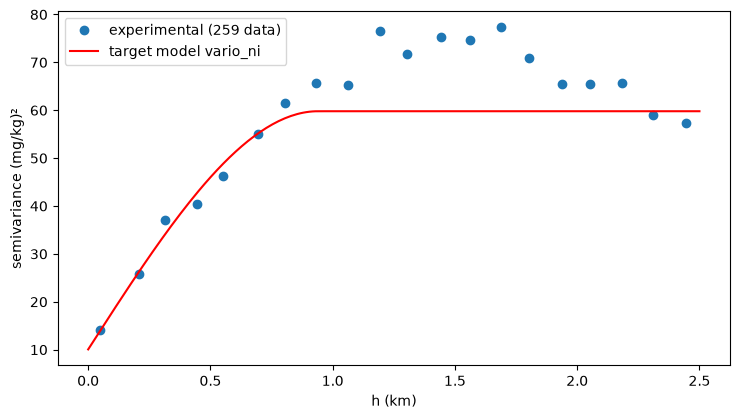

In [3]:
def experimental_variogram(xy, values, maxlag=2.5, n_lags=20):
    d = pdist(xy)
    g = 0.5 * pdist(values[:, None], "sqeuclidean")
    edges = np.linspace(0, maxlag, n_lags + 1)
    h, gam, npairs = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d > lo) & (d <= hi)
        h.append(d[m].mean()); gam.append(g[m].mean()); npairs.append(m.sum())
    return np.array(h), np.array(gam), np.array(npairs)


def spherical(h, nugget, a, sill):
    r = np.minimum(np.asarray(h, float) / a, 1.0)
    return nugget + (sill - nugget) * (1.5 * r - 0.5 * r ** 3)


def fit_spherical(xy, values, sill):
    h, g, n = experimental_variogram(xy, values)
    (nr, a), _ = curve_fit(lambda h, nr, a: spherical(h, nr * sill, a, sill), h, g, p0=[0.3, 1.0],
                           bounds=([0.0, 0.1], [0.95, 4.0]), sigma=1 / np.sqrt(n))
    return [0.0, round(nr * sill, 3), round(a, 3), round(a, 3), round(sill, 3), "spherical"], (h, g)


vario_ni, exp_ni = fit_spherical(xy, ni, ni.var())
ni_ns, _, _ = nscore_forward(ni, tails="linear")
vario_ns, _ = fit_spherical(xy, ni_ns, 1.0)
print("vario_ni (mg/kg, annealing target):", vario_ni)
print("vario_ns (normal scores, SGS)      :", vario_ns)

hh = np.linspace(0, 2.5, 200)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(*exp_ni, "o", label="experimental (259 data)")
ax.plot(hh, spherical(hh, *vario_ni[1:3], vario_ni[4]), "r-", label="target model vario_ni")
ax.set_xlabel("h (km)")
ax.set_ylabel("semivariance (mg/kg)²")
ax.legend()
plt.tight_layout()
plt.show()

The objective uses 10 lags of one cell (100 m) along each of the four default directions, so it controls the variogram up to 1 km along the axes and 1.4 km along the diagonals. That covers the range of about 0.9 km.

In [4]:
N_LAGS = 10
SA_KW = dict(n_lags=N_LAGS)

***
## A First Run with `SimulatedAnnealing`

Fit, simulate one realization, and look at what the optimizer did. `history_` holds $O / O_{\text{init}}$ after each temperature, `n_swaps_` the swaps attempted, and `objective_` the final relative objective.

lattice: 49 x 59 = 2891 nodes, spacing 0.10 km; hard-data nodes: 205 (259 data, some share a node)


one realization: 2.1 s, 57,001 swaps, final O / O_init = 9.9e-04, 3 temperatures


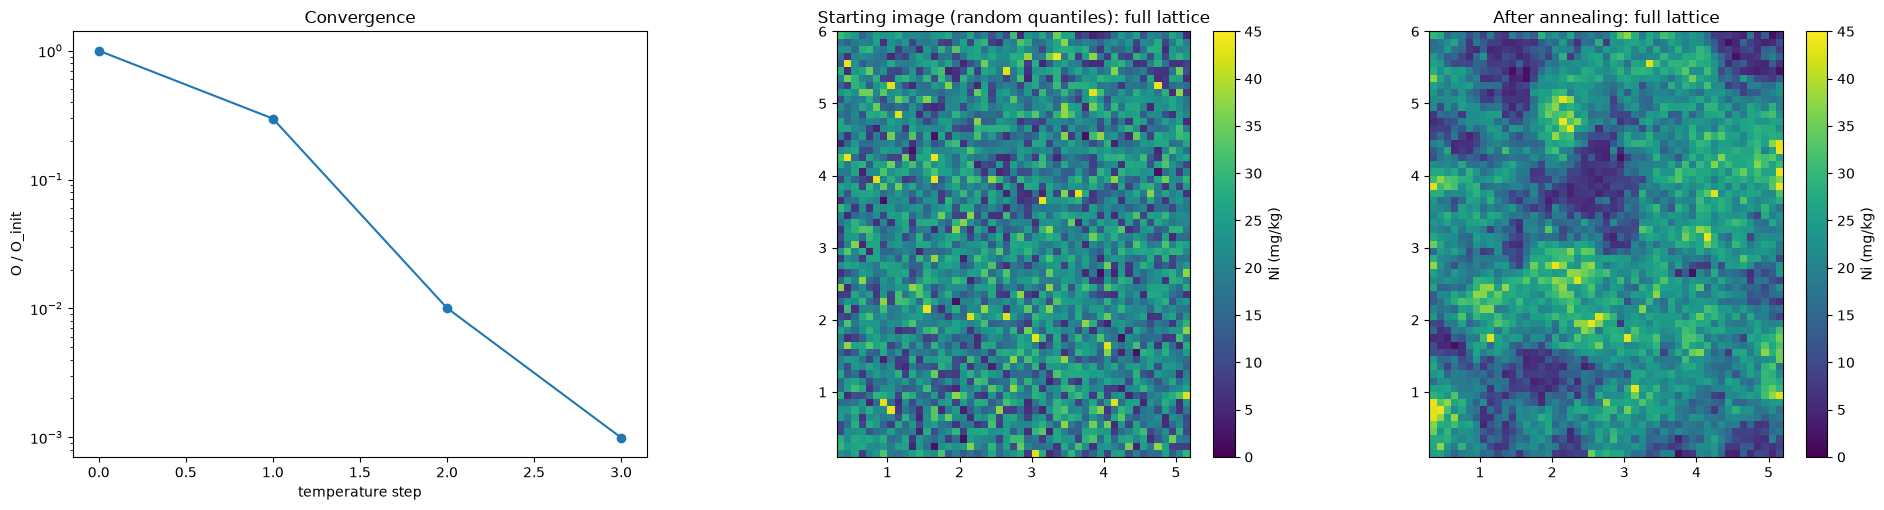

In [5]:
sa = SimulatedAnnealing(vario=vario_ni, **SA_KW).fit(grid, df, "Xloc", "Yloc", "Ni")
lat = sa.lattice_
print(f"lattice: {lat['nx']} x {lat['ny']} = {lat['nx'] * lat['ny']} nodes, spacing {lat['dx']:.2f} km; "
      f"hard-data nodes: {np.isfinite(sa._hard).sum()} (259 data, some share a node)")
t0 = time.perf_counter()
img = sa.simulate_lattice(nsim=1, seed=1)[0]
print(f"one realization: {time.perf_counter() - t0:.1f} s, {sa.n_swaps_[0]:,} swaps, "
      f"final O / O_init = {sa.objective_[0]:.1e}, {len(sa.history_[0]) - 1} temperatures")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
axes[0].semilogy(sa.history_[0], "o-")
axes[0].set_xlabel("temperature step")
axes[0].set_ylabel("O / O_init")
axes[0].set_title("Convergence")
start = SimulatedAnnealing(vario=vario_ni, **SA_KW, max_swaps=1).fit(grid, df, "Xloc", "Yloc", "Ni")
img0 = start.simulate_lattice(nsim=1, seed=1)[0]          # one swap only: essentially the start image
for ax, im_, title in [(axes[1], img0, "Starting image (random quantiles)"), (axes[2], img, "After annealing")]:
    h_ = ax.imshow(im_.T, origin="lower", cmap="viridis", vmin=0, vmax=45,
                   extent=[lat["x0"], lat["x0"] + lat["nx"] * lat["dx"], lat["y0"], lat["y0"] + lat["ny"] * lat["dy"]])
    ax.set_title(title + ": full lattice")
    ax.set_aspect("equal")
    plt.colorbar(h_, ax=ax, label="Ni (mg/kg)", fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

The full lattice includes the nodes outside the irregular study area (the corners of the bounding box); `simulate` drops them. The starting image is white noise with the right histogram, and annealing rearranges it into a spatially continuous field.

Checks on 20 realizations:

* the histogram is exact (each image is a permutation of the start);
* hard data are reproduced at their nodes;
* the same seed reproduces the image;
* `sasim` equals the class.

In [6]:
N_SIM = 20
t0 = time.perf_counter()
lat_reals = sa.simulate_lattice(nsim=N_SIM, seed=2024)
sa_reals = lat_reals[:, sa._grid_idx[:, 0], sa._grid_idx[:, 1]]
print(f"{N_SIM} realizations in {time.perf_counter() - t0:.0f} s; final O/O_init: median {np.median(sa.objective_):.1e}, "
      f"max {sa.objective_.max():.1e}")

free = np.isnan(sa._hard)
start_values = np.sort(img0[free])
same_hist = all(np.allclose(np.sort(lat_reals[r][free]), start_values) for r in range(N_SIM))
record("annealing: histogram of free nodes exactly preserved by swaps", "PASS" if same_hist else "FAIL",
       "sorted values identical to the stratified start in every realization")
hard = np.isfinite(sa._hard)
err = max(np.abs(lat_reals[r][hard] - sa._hard[hard]).max() for r in range(N_SIM))
record("annealing: hard data honoured at their nodes", "PASS" if err == 0 else "FAIL", f"max error {err}")
again = SimulatedAnnealing(vario=vario_ni, **SA_KW).fit(grid, df, "Xloc", "Yloc", "Ni").simulate(nsim=2, seed=2024)
record("annealing: same seed -> identical", "PASS" if np.array_equal(again, sa_reals[:2]) else "FAIL")
one_call = sasim(grid, df, "Xloc", "Yloc", "Ni", vario=vario_ni, nsim=2, seed=2024, **SA_KW)
record("sasim == SimulatedAnnealing(...).simulate", "PASS" if np.array_equal(one_call, sa_reals[:2]) else "FAIL")
record("annealing converged (O/O_init <= 1e-3) in every realization",
       "PASS" if (sa.objective_ <= 1.001e-3).all() else "FAIL", f"max {sa.objective_.max():.1e}")

print(f"\nNi data: mean {ni.mean():.2f}, sd {ni.std():.2f};  annealed grid values: mean {sa_reals.mean():.2f}, "
      f"sd {sa_reals.std(1).mean():.2f}")

20 realizations in 43 s; final O/O_init: median 1.0e-03, max 1.0e-03
✅ [PASS] annealing: histogram of free nodes exactly preserved by swaps  sorted values identical to the stratified start in every realization
✅ [PASS] annealing: hard data honoured at their nodes  max error 0.0


✅ [PASS] annealing: same seed -> identical  


✅ [PASS] sasim == SimulatedAnnealing(...).simulate  
✅ [PASS] annealing converged (O/O_init <= 1e-3) in every realization  max 1.0e-03

Ni data: mean 20.14, sd 7.73;  annealed grid values: mean 20.64, sd 7.48


***
## Variogram Reproduction by Direction

`experimental_variogram(image)` and `target_variogram()` evaluate an image and the target at exactly the lag vectors in the objective: four directions × 10 lags. The realizations should follow the target in **every** direction, because every direction is in the objective. Between the controlled lags, and beyond them, nothing is enforced.

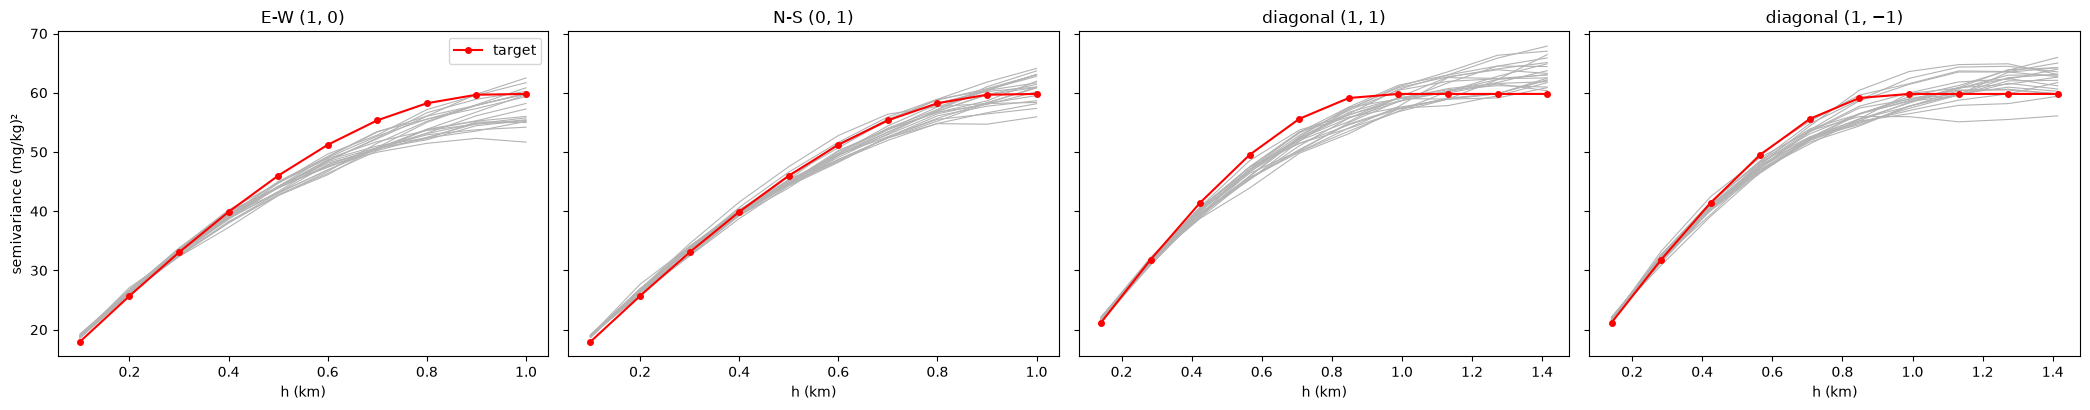

relative error: median 0.032, max 0.072 (E-W (1, 0), lag 7)
✅ [PASS] annealing: variogram within 10% of target at every controlled lag (mean of realizations)  max relative error 0.072


In [7]:
target = sa.target_variogram()[0].reshape(4, N_LAGS)
emp = np.stack([sa.experimental_variogram(lat_reals[r])[0].reshape(4, N_LAGS) for r in range(N_SIM)])
names = ["E-W (1, 0)", "N-S (0, 1)", "diagonal (1, 1)", "diagonal (1, −1)"]
steps = [1.0, 1.0, np.sqrt(2), np.sqrt(2)]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), sharey=True)
for d, ax in enumerate(axes):
    h = np.arange(1, N_LAGS + 1) * steps[d] * CELL
    for r in range(N_SIM):
        ax.plot(h, emp[r, d], color="0.7", lw=0.8)
    ax.plot(h, target[d], "ro-", ms=4, label="target")
    ax.set_title(names[d])
    ax.set_xlabel("h (km)")
axes[0].set_ylabel("semivariance (mg/kg)²")
axes[0].legend()
plt.tight_layout()
plt.show()
rel = np.abs(emp.mean(0) - target) / target
worst = np.unravel_index(rel.argmax(), rel.shape)
print(f"relative error: median {np.median(rel):.3f}, max {rel.max():.3f} ({names[worst[0]]}, lag {worst[1] + 1})")
record("annealing: variogram within 10% of target at every controlled lag (mean of realizations)",
       "PASS" if rel.max() < 0.10 else "FAIL", f"max relative error {rel.max():.3f}")

At the controlled lags the realizations sit almost exactly on the target, in all four directions, with very little spread between realizations. That is the optimizer at work, and it is the main thing annealing does well. The remaining error (a few per cent, largest at the shortest lags) is set by the stopping rule: annealing stops when $O$ falls to `tol` $= 10^{-3}$ of its initial value. Section 8 tightens it. The narrow spread is also a reminder: the realizations agree with the *model*, not with the data. Sequential methods reproduce the model variogram only on average, with realistic ergodic fluctuations between realizations.

***
## The Annealing Schedule

Three schedules are compared, each on 3 realizations:

| Schedule | `t0` | `reduction` | Character |
|---|---|---|---|
| quench | 0.01 | 0.01 | almost greedy descent |
| default | 1.0 | 0.1 | GSLIB-style fast annealing |
| slow | 2.0 | 0.5 | many temperature steps |
| default, `tol = 1e-4` | 1.0 | 0.1 | default schedule, stricter stopping rule |

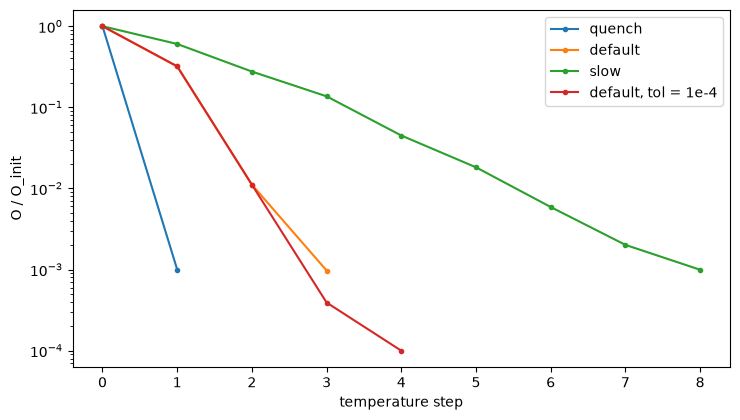

,seconds / realization,swaps / realization,temperatures,final O/O_init,max rel. variogram error
schedule,,,,,
quench,0.5913,15515.3333,1.0,0.0010,0.1242
default,2.1242,56578.3333,3.0,0.0010,0.1109
slow,7.0828,187386.0000,8.0,0.0010,0.0740
"default, tol = 1e-4",3.3915,90527.6667,4.0,0.0001,0.0448


In [8]:
schedules = {"quench": dict(t0=0.01, reduction=0.01), "default": dict(t0=1.0, reduction=0.1),
             "slow": dict(t0=2.0, reduction=0.5), "default, tol = 1e-4": dict(t0=1.0, reduction=0.1, tol=1e-4)}
rows, hist = [], {}
for name, kw in schedules.items():
    s = SimulatedAnnealing(vario=vario_ni, **SA_KW, **kw).fit(grid, df, "Xloc", "Yloc", "Ni")
    t0 = time.perf_counter()
    lr = s.simulate_lattice(nsim=3, seed=7)
    hist[name] = s.history_[0]
    vg_err = np.mean([np.abs(s.experimental_variogram(lr[i])[0] / s.target_variogram()[0] - 1).max() for i in range(3)])
    rows.append({"schedule": name, "seconds / realization": (time.perf_counter() - t0) / 3,
                 "swaps / realization": s.n_swaps_.mean(), "temperatures": np.mean([len(h) - 1 for h in s.history_]),
                 "final O/O_init": s.objective_.mean(), "max rel. variogram error": vg_err})
sched = pd.DataFrame(rows).set_index("schedule")
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for name, h in hist.items():
    ax.semilogy(h, "o-", ms=3, label=name)
ax.set_xlabel("temperature step")
ax.set_ylabel("O / O_init")
ax.legend()
plt.tight_layout()
plt.show()
sched.round(4)

All four schedules reach the stopping tolerance. For a variogram objective the landscape is benign, so even an almost greedy **quench** (one temperature step, 0.6 s) gets there, about 4× faster than the default. The schedule does affect *how well* the variogram is matched at the end:

| | max relative variogram error in one realization |
|---|---|
| quench | 12% |
| default | 11% |
| slow | 7% |
| default with `tol = 1e-4` | 4.5% |

Both a slower schedule and a stricter `tol` buy precision with time. The stopping rule is the more direct lever: the default schedule with `tol = 1e-4` was more precise than the slow schedule and took half the time.

For objectives with competing components (Section 10), or for categorical images, where swaps can create isolated pixels that a greedy search never removes, a slower schedule is worth more.

***
## Conditioning and Local Accuracy: Annealing vs SGS

The data are fixed at their nodes, but Section 2.6 warned that their influence on the neighbouring nodes is weak. Three diagnostics compare 20 annealed realizations with 20 SGS realizations on the same 100 m grid:

1. **Continuity across the data:** the mean squared difference between a hard-data node and its four lattice neighbours, against the same quantity between other nodes. In a realization without conditioning artefacts the two agree, at about $2\gamma(100\text{ m})$.
2. **E-type maps:** does the mean of the realizations reflect the data?
3. **Held-out sites:** RMSE of the E-type and coverage of the 80% interval at the 100 validation sites, each read at its nearest grid node.

mean squared difference to the 4 neighbours, (mg/kg)²;  model 2*gamma(0.1 km) = 35.9


,around hard data,elsewhere,ratio
annealing,45.95,36.94,1.24
SGS,39.67,39.93,0.99


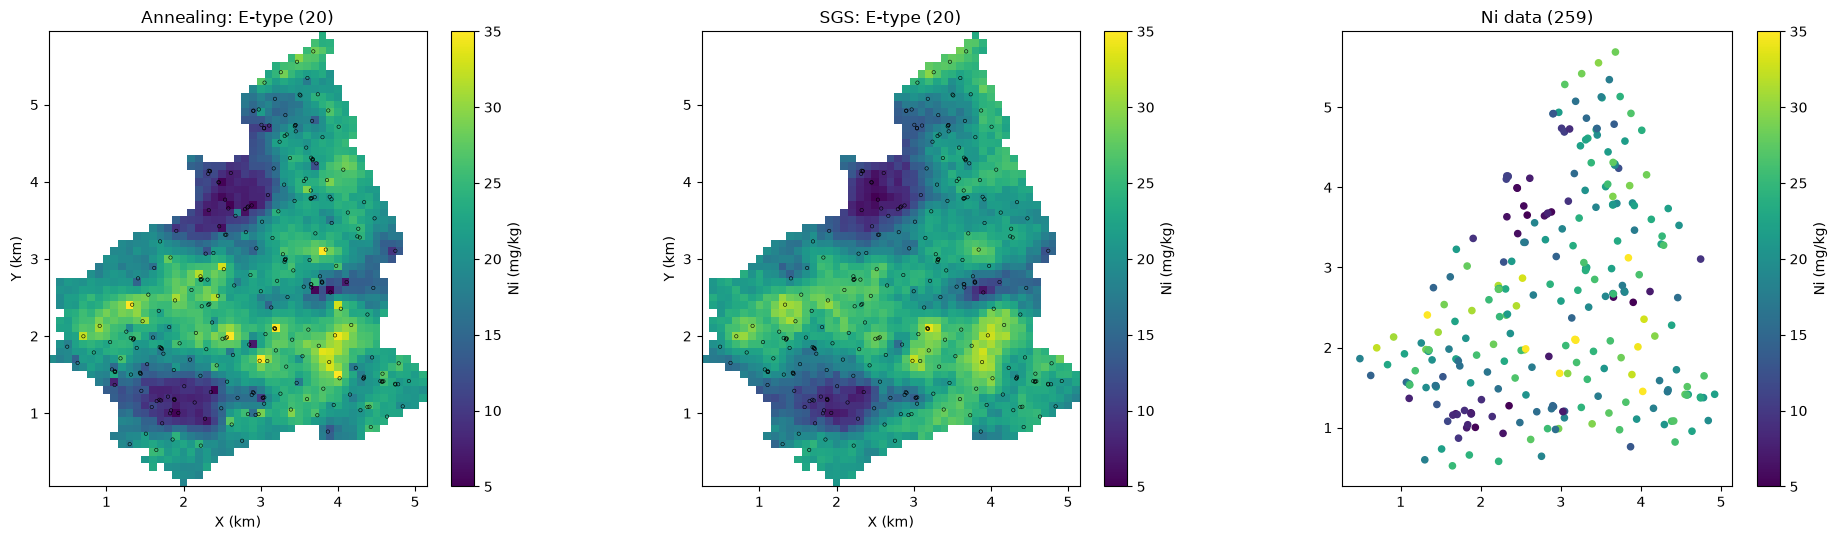

In [9]:
sgs_reals = sgsim_gpu(grid, df, "Xloc", "Yloc", "Ni", vario_ns, num_points=16, radius=1.5, nsim=N_SIM,
                      seed=2024, zmin=0.0, use_gpu=USE_GPU)
sgs_lat = np.full_like(lat_reals, np.nan)
sgs_lat[:, sa._grid_idx[:, 0], sa._grid_idx[:, 1]] = sgs_reals
in_grid = np.zeros(sa._hard.shape, bool)
in_grid[sa._grid_idx[:, 0], sa._grid_idx[:, 1]] = True


def neighbour_msd(images, mask):
    # mean squared difference between masked nodes and their 4 lattice neighbours (inside the grid)
    out = []
    for im_ in images:
        d2 = []
        for di, dj in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
            nb = np.roll(np.roll(im_, di, 0), dj, 1)
            ok = mask & np.roll(np.roll(in_grid, di, 0), dj, 1) & in_grid
            d2.append((im_[ok] - nb[ok]) ** 2)
        out.append(np.concatenate(d2).mean())
    return np.mean(out)


hard_mask = hard & in_grid
free_mask = free & in_grid
cont = pd.DataFrame({
    "around hard data": [neighbour_msd(lat_reals, hard_mask), neighbour_msd(sgs_lat, hard_mask)],
    "elsewhere": [neighbour_msd(lat_reals, free_mask), neighbour_msd(sgs_lat, free_mask)]},
    index=["annealing", "SGS"])
cont["ratio"] = cont["around hard data"] / cont["elsewhere"]
print("mean squared difference to the 4 neighbours, (mg/kg)²;  model 2*gamma(0.1 km) =",
      round(2 * spherical(0.1, *vario_ni[1:3], vario_ni[4]), 1))
display(cont.round(2))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_map(axes[0], sa_reals.mean(0), "Annealing: E-type (20)", vmin=5, vmax=35, points=xy)
show_map(axes[1], sgs_reals.mean(0), "SGS: E-type (20)", vmin=5, vmax=35, points=xy)
sc = axes[2].scatter(xy[:, 0], xy[:, 1], c=ni, s=20, cmap="viridis", vmin=5, vmax=35)
axes[2].set_aspect("equal")
axes[2].set_title("Ni data (259)")
plt.colorbar(sc, ax=axes[2], label="Ni (mg/kg)", fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [10]:
N_VAL = 40
node_test = cKDTree(grid).query(xy_test)[1]
truth = test["Ni"].to_numpy(float)
t0 = time.perf_counter()
sa_val = SimulatedAnnealing(vario=vario_ni, **SA_KW).fit(grid, df, "Xloc", "Yloc", "Ni").simulate(nsim=N_VAL, seed=11)
print(f"{N_VAL} annealing realizations in {time.perf_counter() - t0:.0f} s")
sgs_val = sgsim_gpu(grid, df, "Xloc", "Yloc", "Ni", vario_ns, num_points=16, radius=1.5, nsim=N_VAL, seed=11,
                    zmin=0.0, use_gpu=USE_GPU)


# validation sites whose nearest node holds a hard datum get that datum in every annealed realization
grid_hard = np.isfinite(sa._hard[sa._grid_idx[:, 0], sa._grid_idx[:, 1]])
on_hard = grid_hard[node_test]
print(f"{on_hard.sum()} of {len(truth)} validation sites fall on a hard-data node of the 100 m lattice")


def score(name, ens, sites=slice(None)):
    e = ens[:, node_test][:, sites]
    t = truth[sites]
    et = e.mean(0)
    lo, hi = np.percentile(e, [10, 90], axis=0)
    return {"method": name, "n sites": len(t), "RMSE": np.sqrt(np.mean((et - t) ** 2)), "corr": np.corrcoef(et, t)[0, 1],
            "cover80": np.mean((t >= lo) & (t <= hi)), "width80": np.mean(hi - lo)}


val_table = pd.DataFrame([score("annealing, all sites", sa_val), score("SGS, all sites", sgs_val),
                          score("annealing, free-node sites", sa_val, ~on_hard),
                          score("SGS, free-node sites", sgs_val, ~on_hard)]).set_index("method")
display(val_table.round(3))
a, g_ = val_table.loc["annealing, free-node sites"], val_table.loc["SGS, free-node sites"]
record("annealing 80% intervals under-cover at held-out free-node sites (expected: no probability model)",
       "PASS" if a.cover80 < 0.65 and 0.65 <= g_.cover80 <= 0.95 else "FAIL",
       f"coverage annealing {a.cover80:.2f} (width {a.width80:.1f}), SGS {g_.cover80:.2f} (width {g_.width80:.1f})")

40 annealing realizations in 85 s


38 of 100 validation sites fall on a hard-data node of the 100 m lattice


,n sites,RMSE,corr,cover80,width80
method,,,,,
"annealing, all sites",100,5.623,0.777,0.370,7.811
"SGS, all sites",100,5.718,0.773,0.780,12.120
"annealing, free-node sites",62,6.358,0.644,0.597,12.599
"SGS, free-node sites",62,5.876,0.710,0.742,12.957


✅ [PASS] annealing 80% intervals under-cover at held-out free-node sites (expected: no probability model)  coverage annealing 0.60 (width 12.6), SGS 0.74 (width 13.0)


* **Discontinuities around the data.** In the annealed realizations a hard-data node differs from its neighbours by 24% more (mean squared difference 46 vs 37 (mg/kg)²) than other nodes do from theirs. In SGS the two are equal (ratio 0.99). The hard data are fixed, but the objective barely notices how they connect to their surroundings. This is the conditioning artefact described in Section 2.6.
* **Held-out sites.** 38 of the 100 validation sites have a hard datum at their nearest 100 m node. There, every annealed realization returns that datum, a neighbouring sample, with zero spread. Scores over all sites are therefore misleading: annealing appears as accurate as SGS, with absurdly narrow intervals (coverage 0.37).
* **At the 62 sites with a free node**, SGS is clearly better:
    * E-type RMSE 5.88 vs 6.36 mg/kg, and correlation with the truth 0.71 vs 0.64;
    * the intervals are equally wide, but SGS's cover 74% of the true values against annealing's 60%.

  Annealing's local distributions are both less accurate and less calibrated, because nothing in the objective ties them to the data the way kriging does.
* **E-type maps.** The annealed E-type is noisier, with isolated spots at the data, while the SGS E-type is a smooth, kriging-like surface.

***
## A Secondary Variable: the Correlation Component

Chromium is strongly related to nickel in the Jura soils. A kriged chromium map (from all 359 samples) is passed as `secondary`, which adds the correlation component $O_\rho$. The target correlation defaults to the correlation between Ni and Cr at the data (`secondary_col="Cr"`). The weight of the correlation component relative to the variogram is varied with `component_weights`.

In [11]:
xy_all = df_all[["Xloc", "Yloc"]].to_numpy(float)
cr_all = df_all["Cr"].to_numpy(float)
vg_cr = Variogram(xy_all, cr_all, model="spherical", n_lags=15).fit()
cr_grid = np.asarray(OrdinaryKriging(vg_cr).fit(xy_all, cr_all).predict(grid), float)

rows, corr_reals = [], {}
for w in [0.0, 1.0, 5.0]:
    s = SimulatedAnnealing(vario=vario_ni, **SA_KW, component_weights={"variogram": 1.0, "correlation": w})
    s.fit(grid, df, "Xloc", "Yloc", "Ni", secondary=cr_grid, secondary_col="Cr")
    r_ = s.simulate(nsim=N_SIM, seed=11)
    corr_reals[w] = r_
    rho_real = np.array([np.corrcoef(r_[i], cr_grid)[0, 1] for i in range(len(r_))])
    lat_r = s.simulate_lattice(nsim=1, seed=5)[0]
    vg_err = np.abs(s.experimental_variogram(lat_r)[0] / s.target_variogram()[0] - 1).max()
    rows.append({"correlation weight": w, "target rho": s.rho_target_, "realized rho (mean)": rho_real.mean(),
                 "realized rho (sd)": rho_real.std(), "max rel. variogram error": vg_err,
                 **{k: v for k, v in score("", r_, ~on_hard).items() if k not in ("method", "n sites")}})
corr_table = pd.DataFrame(rows).set_index("correlation weight")
corr_table.round(3)

,target rho,realized rho (mean),realized rho (sd),max rel. variogram error,RMSE,corr,cover80,width80
correlation weight,,,,,,,,
0.0,0.701,0.456,0.032,0.110,6.403,0.636,0.565,12.181
1.0,0.701,0.741,0.006,0.116,5.683,0.749,0.597,10.285
5.0,0.701,0.742,0.006,0.157,5.652,0.754,0.565,9.853


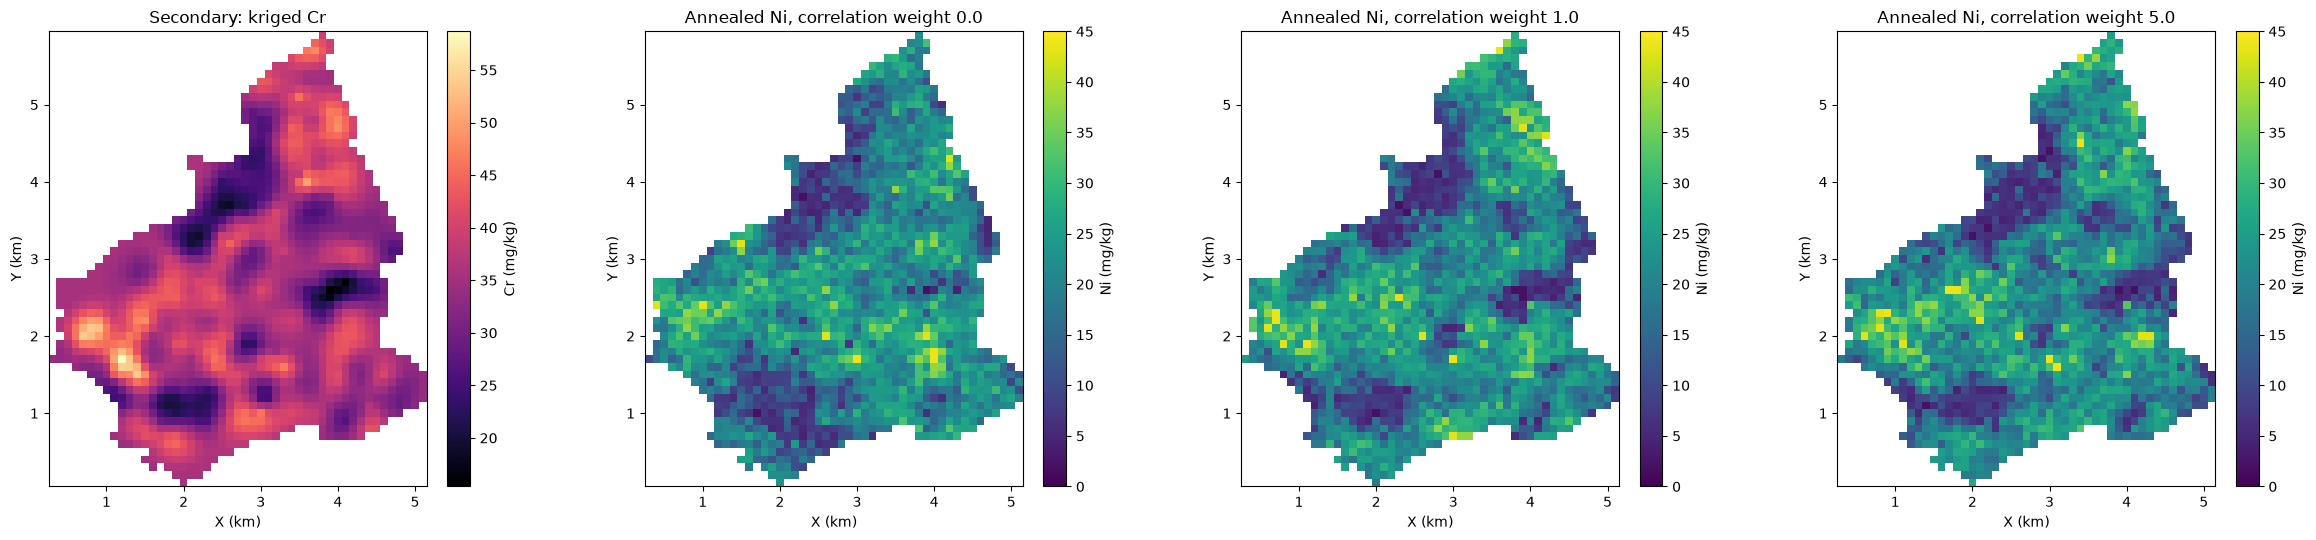

✅ [PASS] correlation component: realized rho within 0.05 of target (weight 1)  target 0.701, realized 0.741


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
show_map(axes[0], cr_grid, "Secondary: kriged Cr", cmap="magma", label="Cr (mg/kg)")
for ax, w in zip(axes[1:], [0.0, 1.0, 5.0]):
    show_map(ax, corr_reals[w][0], f"Annealed Ni, correlation weight {w}", vmin=0, vmax=45)
plt.tight_layout()
plt.show()
w1 = corr_table.loc[1.0]
record("correlation component: realized rho within 0.05 of target (weight 1)",
       "PASS" if abs(w1["realized rho (mean)"] - w1["target rho"]) < 0.05 else "FAIL",
       f"target {w1['target rho']:.3f}, realized {w1['realized rho (mean)']:.3f}")

* **Without the correlation component** (weight 0), the annealed Ni correlates 0.46 with the Cr map, which is what the hard data alone impose.
* **With weight 1**, the realized correlation reaches 0.74 against the target 0.70. The objective stops at `tol` of its initial value, so it does not land exactly. The between-realization spread of the correlation (0.006) is tiny. As with the variogram, annealing enforces the target statistic in every realization rather than on average.
* **Raising the weight to 5** buys nothing for the correlation but costs variogram precision (maximum error 16% against 12%). Competing components trade off through `component_weights`.
* **The secondary improves the E-type** at the free-node validation sites (RMSE 6.40 → 5.68 mg/kg, correlation 0.64 → 0.75), but not the calibration: coverage stays near 0.6.

***
## Categorical Annealing: Rock Type

With `indicator_varios={class: vario}` the objective becomes the sum of the indicator-variogram mismatches of the five rock types. Because swaps keep the starting values, the **class proportions are exact**. In [sequential indicator simulation](05_07_04_sicosim.ipynb) the same rock types drifted (Kimmeridgian 0.44 against 0.36 in the samples).

The indicator variogram of each class is fitted with sill $p_c(1 - p_c)$. The geology map is the reference, as in the SIS notebook.

In [13]:
CLASSES = [1, 2, 3, 4, 5]
rock = df["Rock"].to_numpy(float)
ind_varios = {c: fit_spherical(xy, (rock == c).astype(float), (rock == c).mean() * (1 - (rock == c).mean()))[0]
              for c in CLASSES}
for c, v in ind_varios.items():
    print(f"{ROCKS[c]:13s} p = {(rock == c).mean():.3f}  vario = {v}")

N_CAT = 8
t0 = time.perf_counter()
sac = SimulatedAnnealing(indicator_varios=ind_varios, **SA_KW).fit(grid, df, "Xloc", "Yloc", "Rock")
cat_lat = sac.simulate_lattice(nsim=N_CAT, seed=3)
cat_reals = cat_lat[:, sac._grid_idx[:, 0], sac._grid_idx[:, 1]]
print(f"\n{N_CAT} categorical realizations in {time.perf_counter() - t0:.0f} s; final O/O_init median "
      f"{np.median(sac.objective_):.1e}")

free_c = np.isnan(sac._hard)
props_lat = np.array([[np.mean(cat_lat[r][free_c] == c) for c in CLASSES] for r in range(N_CAT)])
counts = np.stack([(cat_reals == c).mean(0) for c in CLASSES])
mode = np.array(CLASSES)[counts.argmax(0)]
cat_table = pd.DataFrame({
    "samples (259)": [(rock == c).mean() for c in CLASSES],
    "annealing, free lattice nodes": props_lat.mean(0),
    "sd over realizations": props_lat.std(0),
    "annealing, study-area nodes": [(cat_reals == c).mean() for c in CLASSES],
    "geology map": [(grid_rock == c).mean() for c in CLASSES]}, index=[ROCKS[c] for c in CLASSES])
display(cat_table.round(4))
print(f"agreement with the geology map: most probable class {np.mean(mode == grid_rock):.3f}, "
      f"per realization {np.mean(cat_reals == grid_rock):.3f}")
record("categorical annealing: class proportions identical in every realization (free nodes)",
       "PASS" if props_lat.std(0).max() < 1e-12 else "FAIL", f"max sd over realizations {props_lat.std(0).max():.1e}")

Argovian      p = 0.208  vario = [0.0, np.float64(0.029), np.float64(1.189), np.float64(1.189), np.float64(0.165), 'spherical']
Kimmeridgian  p = 0.363  vario = [0.0, np.float64(0.078), np.float64(1.346), np.float64(1.346), np.float64(0.231), 'spherical']
Sequanian     p = 0.259  vario = [0.0, np.float64(0.0), np.float64(0.568), np.float64(0.568), np.float64(0.192), 'spherical']
Portlandian   p = 0.012  vario = [0.0, np.float64(0.0), np.float64(0.363), np.float64(0.363), np.float64(0.011), 'spherical']
Quaternary    p = 0.158  vario = [0.0, np.float64(0.0), np.float64(0.378), np.float64(0.378), np.float64(0.133), 'spherical']



8 categorical realizations in 216 s; final O/O_init median 9.5e-04


,samples (259),"annealing, free lattice nodes",sd over realizations,"annealing, study-area nodes",geology map
Argovian,0.2085,0.2085,0.0,0.2025,0.2026
Kimmeridgian,0.3629,0.3630,0.0,0.3838,0.3448
Sequanian,0.2587,0.2587,0.0,0.2618,0.2636
Portlandian,0.0116,0.0115,0.0,0.0110,0.0558
Quaternary,0.1583,0.1582,0.0,0.1409,0.1331


agreement with the geology map: most probable class 0.642, per realization 0.570
✅ [PASS] categorical annealing: class proportions identical in every realization (free nodes)  max sd over realizations 5.6e-17


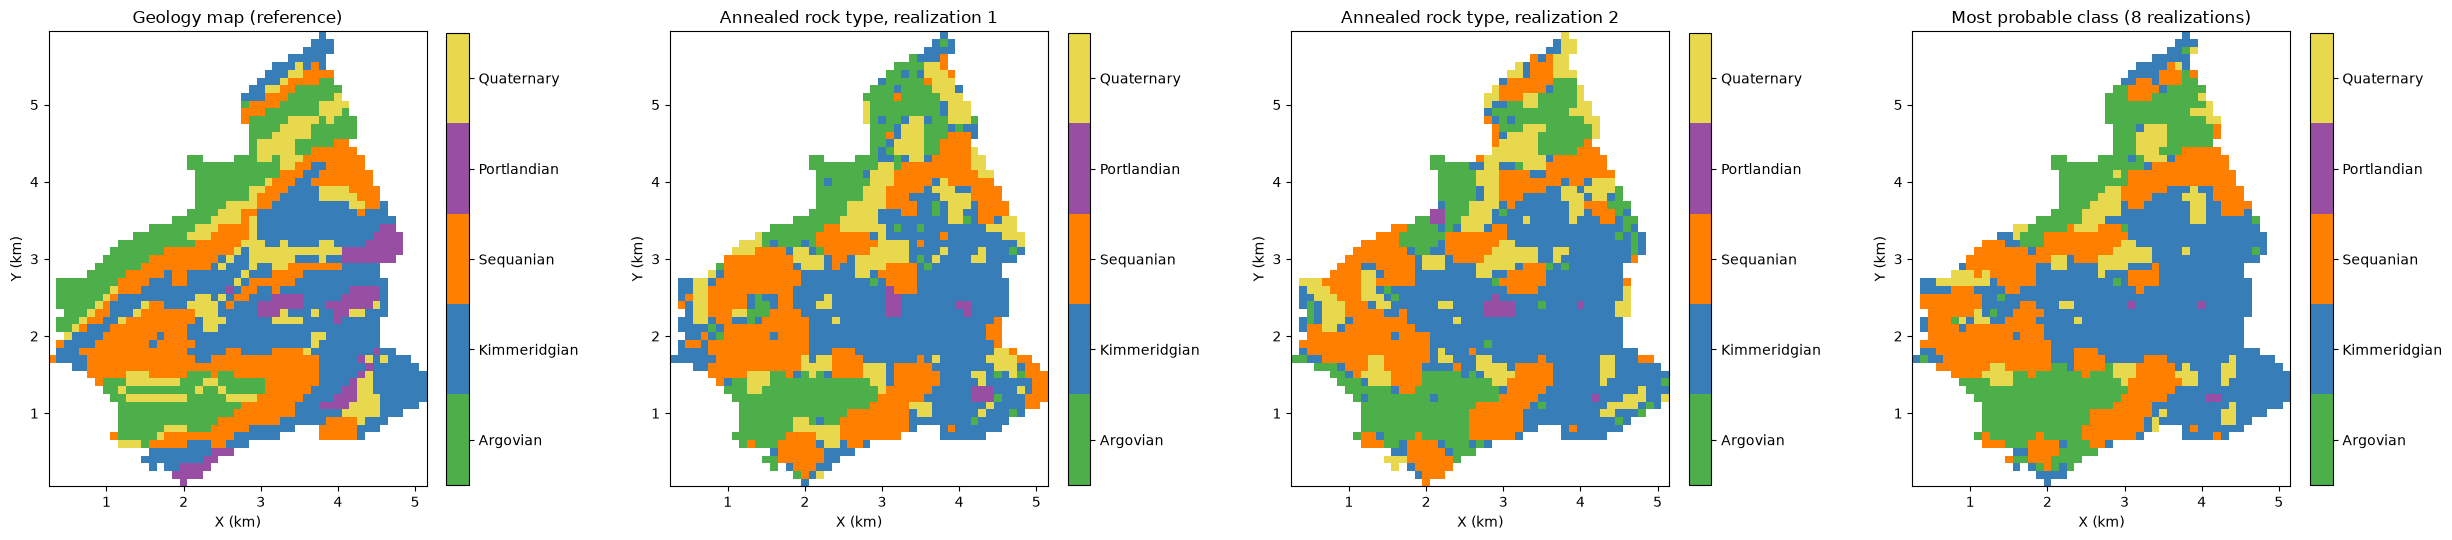

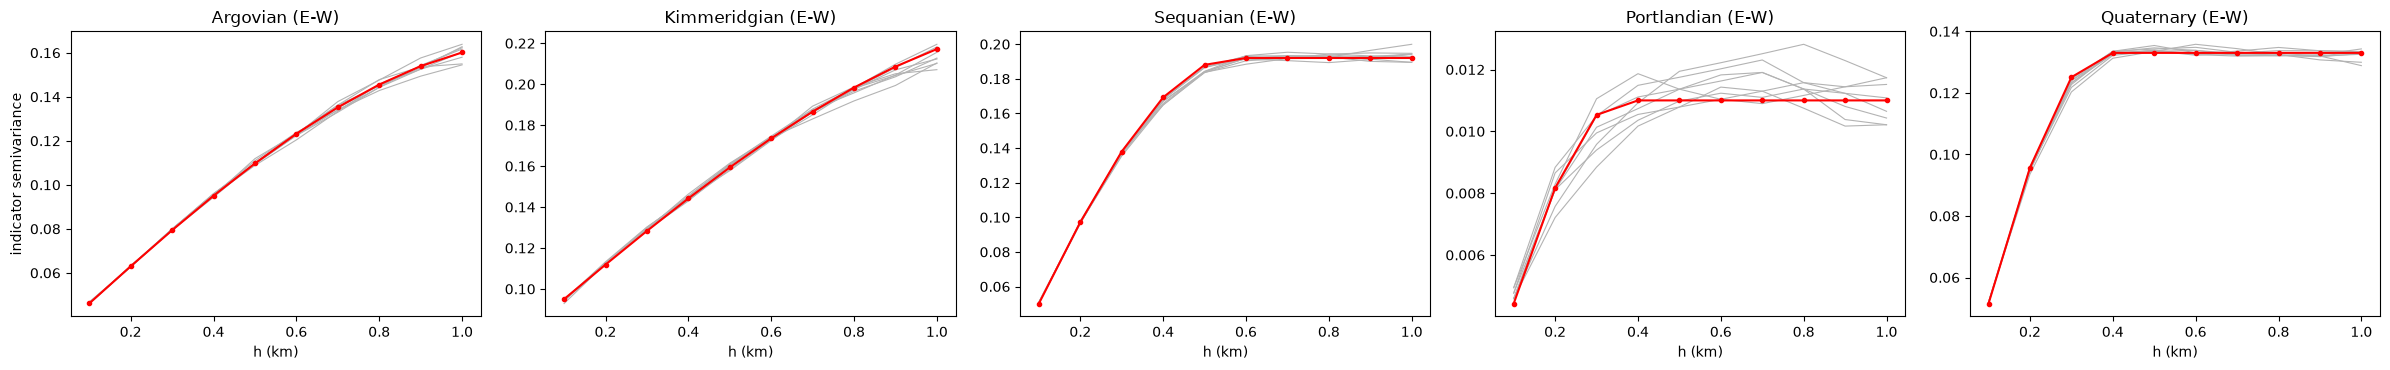

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.5))
show_rock(axes[0], grid_rock, "Geology map (reference)")
show_rock(axes[1], cat_reals[0], "Annealed rock type, realization 1")
show_rock(axes[2], cat_reals[1], "Annealed rock type, realization 2")
show_rock(axes[3], mode, f"Most probable class ({N_CAT} realizations)")
plt.tight_layout()
plt.show()

tgt_c = sac.target_variogram().reshape(len(CLASSES), 4, N_LAGS)
emp_c = np.stack([sac.experimental_variogram(cat_lat[r]).reshape(len(CLASSES), 4, N_LAGS) for r in range(N_CAT)])
fig, axes = plt.subplots(1, 5, figsize=(24, 3.8))
h = np.arange(1, N_LAGS + 1) * CELL
for k, ax in enumerate(axes):
    for r in range(N_CAT):
        ax.plot(h, emp_c[r, k, 0], color="0.7", lw=0.8)
    ax.plot(h, tgt_c[k, 0], "ro-", ms=3)
    ax.set_title(f"{ROCKS[CLASSES[k]]} (E-W)")
    ax.set_xlabel("h (km)")
axes[0].set_ylabel("indicator semivariance")
plt.tight_layout()
plt.show()

* **Proportions are exact.** On the free lattice nodes every realization has exactly the target proportions (standard deviation over realizations about $10^{-17}$). Sequential indicator simulation cannot guarantee that. Over the study-area nodes alone the proportions differ a little: Kimmeridgian 0.38 against 0.36, because the lattice nodes outside the irregular boundary also take part of the histogram. If the proportions must hold inside an irregular area, use a grid that fills the lattice, or pass a mask by simulating on the bounding box and discarding the outside.
* **Patterns.** The realizations have patchy, map-like units with the target indicator variograms (E-W shown). The most probable class matches the geology map at 64% of the nodes, and single realizations at 57%. Portlandian keeps its sample proportion (1.1%), far below its 5.6% on the map, because annealing can only reproduce the proportions it is given. A better target (for example from the map, through `target_values`) would have to come from outside the samples.
* **Cost.** Categorical annealing took about 26 s per realization, roughly ten times more than the continuous case on the same lattice: five indicator variograms per swap, and more swaps to converge.

***
## Visualization of Spatial Uncertainty

The 20 continuous realizations from Section 6 are used for an animation and conditional quantile maps. Read them with Section 9 in mind: the spread between annealed realizations is a by-product of the search, not a calibrated probability.

### Animated display of realizations

In [15]:
plt.rcParams["animation.embed_limit"] = 50
fig_anim, ax_anim = plt.subplots(figsize=(7.2, 7.6))
im_anim = ax_anim.imshow(to_image(sa_reals[0]), origin="lower", extent=EXTENT, cmap="viridis", vmin=0, vmax=45,
                         interpolation="nearest")
ax_anim.scatter(xy[:, 0], xy[:, 1], s=6, facecolors="none", edgecolors="w", linewidths=0.4)
plt.colorbar(im_anim, ax=ax_anim, label="Ni (mg/kg)", fraction=0.046, pad=0.04)
ax_anim.set_xlabel("X (km)")
ax_anim.set_ylabel("Y (km)")
title_anim = ax_anim.set_title(f"Annealed Ni, realization 1 / {N_SIM}")


def _update(frame):
    im_anim.set_data(to_image(sa_reals[frame]))
    title_anim.set_text(f"Annealed Ni, realization {frame + 1} / {N_SIM}")
    return im_anim, title_anim


anim = FuncAnimation(fig_anim, _update, frames=N_SIM, interval=500, blit=False, repeat=True)
plt.close(fig_anim)
display(HTML(anim.to_jshtml()))

### Conditional quantile maps (q10, median, q90)

The 0.10, 0.50 and 0.90 quantiles over the annealed realizations at each node, with the same maps from SGS for comparison.

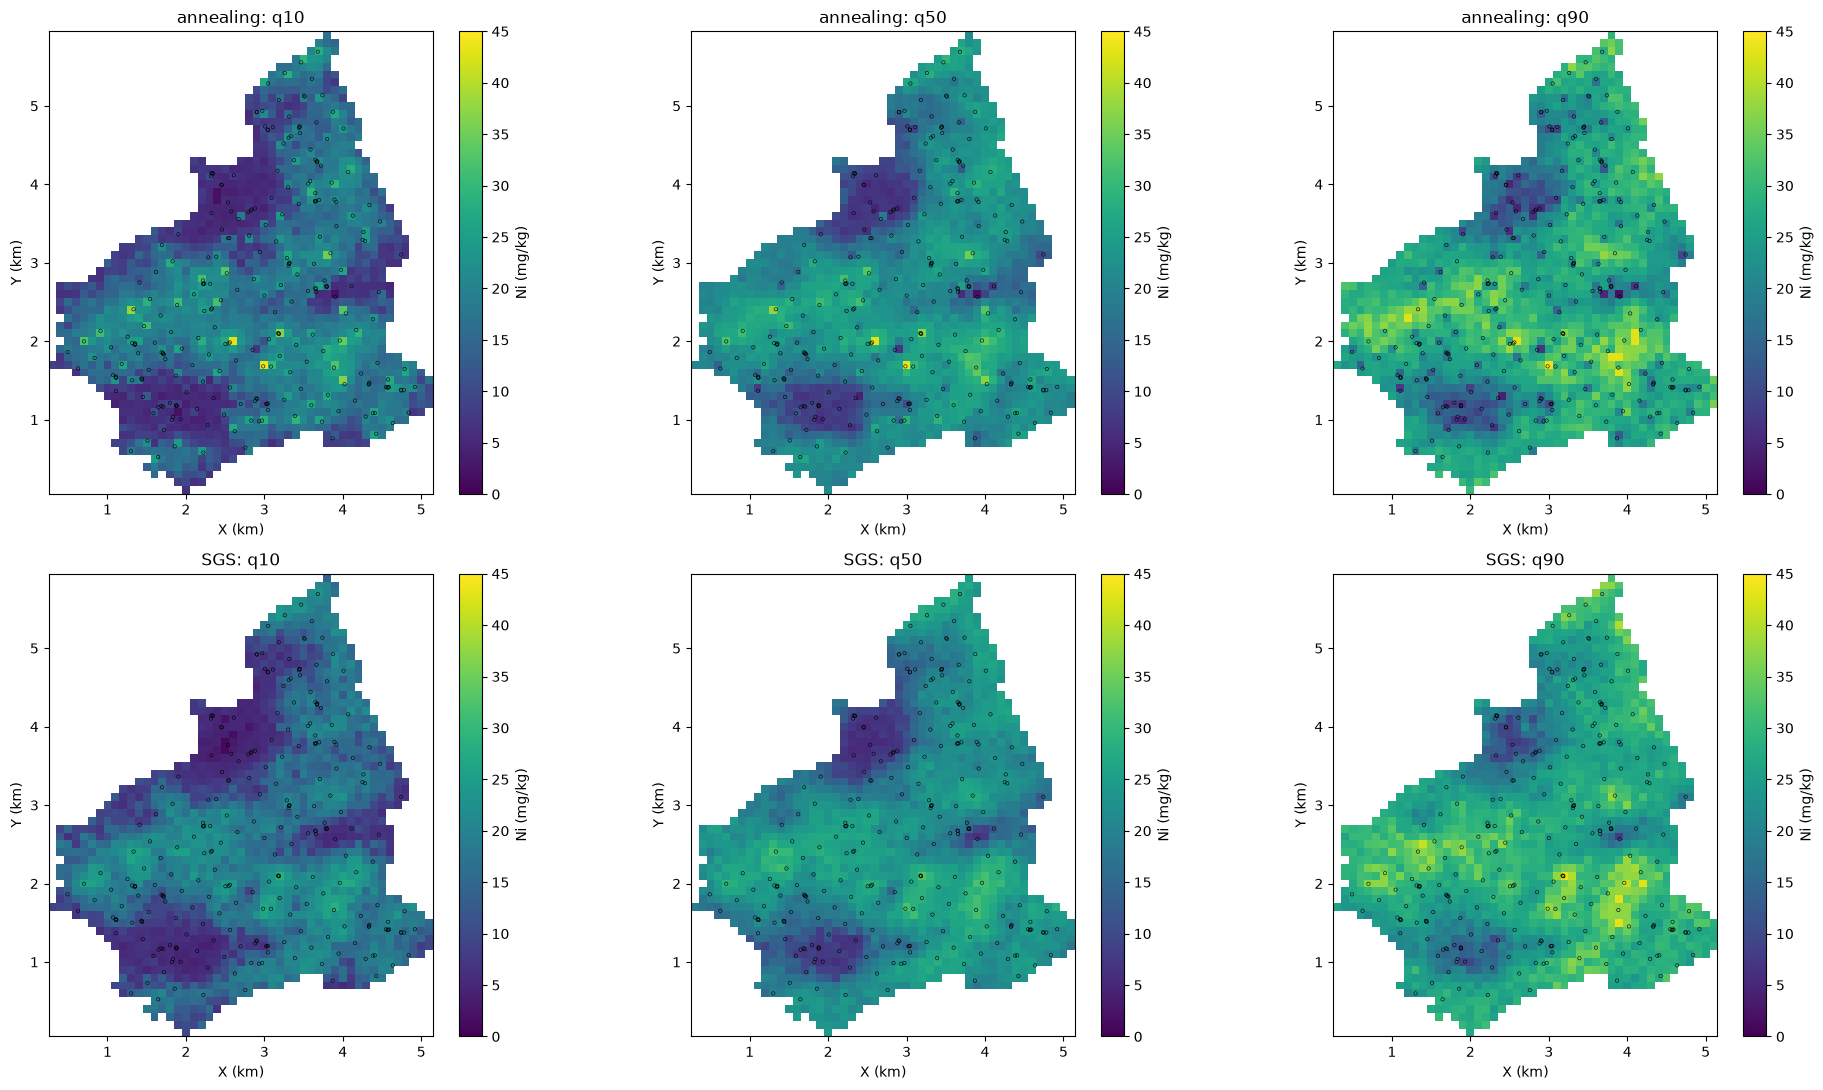

annealing : mean width of the 80% interval 10.9 mg/kg
SGS       : mean width of the 80% interval 11.9 mg/kg


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for row, (name, r_) in enumerate([("annealing", sa_reals), ("SGS", sgs_reals)]):
    for ax, q in zip(axes[row], [0.1, 0.5, 0.9]):
        show_map(ax, np.quantile(r_, q, axis=0), f"{name}: q{int(q * 100)}", vmin=0, vmax=45, points=xy)
plt.tight_layout()
plt.show()
for name, r_ in [("annealing", sa_reals), ("SGS", sgs_reals)]:
    q10, q90 = np.quantile(r_, [0.1, 0.9], axis=0)
    print(f"{name:10s}: mean width of the 80% interval {np.mean(q90 - q10):.1f} mg/kg")

***
## Run Time

The default swap budget, swaps per temperature and scaling sample all grow with the number of free lattice nodes, so the cost per realization grows at least linearly with the lattice size. One continuous realization on the 100 m lattice and one on the full 50 m lattice:

In [17]:
rows = []
for label, g_ in [("100 m (2,891 lattice nodes)", grid), ("50 m (11,349 lattice nodes)", grid50)]:
    s = SimulatedAnnealing(vario=vario_ni, **SA_KW).fit(g_, df, "Xloc", "Yloc", "Ni")
    t0 = time.perf_counter()
    s.simulate(nsim=1, seed=1)
    sec = time.perf_counter() - t0
    rows.append({"lattice": label, "seconds": sec, "swaps": int(s.n_swaps_[0]),
                 "microseconds / swap": 1e6 * sec / s.n_swaps_[0], "final O/O_init": s.objective_[0]})
pd.DataFrame(rows).set_index("lattice").round(4)

,seconds,swaps,microseconds / swap,final O/O_init
lattice,,,,
"100 m (2,891 lattice nodes)",2.1589,57001,37.8744,0.001
"50 m (11,349 lattice nodes)",9.5506,254969,37.4580,0.001


Each swap costs about 36 µs on either lattice. The default budget scales with the lattice: 57,000 swaps on the 2,891-node lattice and 255,000 on the 11,349-node one. One realization therefore takes about 2 s at 100 m and 9 s at 50 m for the continuous variogram objective. Categorical objectives cost about ten times more (Section 11). With no GPU engine, large grids and many realizations need a time budget. The quench schedule (Section 8) or a looser `tol` are the main ways to save time.

***
## Summary and Conclusions

In [18]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,annealing: histogram of free nodes exactly pre...,PASS,sorted values identical to the stratified star...
1,annealing: hard data honoured at their nodes,PASS,max error 0.0
2,annealing: same seed -> identical,PASS,
3,sasim == SimulatedAnnealing(...).simulate,PASS,
4,annealing converged (O/O_init <= 1e-3) in ever...,PASS,max 1.0e-03
5,annealing: variogram within 10% of target at e...,PASS,max relative error 0.072
6,annealing 80% intervals under-cover at held-ou...,PASS,"coverage annealing 0.60 (width 12.6), SGS 0.74..."
7,correlation component: realized rho within 0.0...,PASS,"target 0.701, realized 0.741"
8,categorical annealing: class proportions ident...,PASS,max sd over realizations 5.6e-17


- **Simulated annealing** treats simulation as optimization. It swaps values of a random image until an objective made of target statistics is small. Swaps keep the histogram **exactly**, and hard data are fixed at their nodes. Both were checked on every realization.
- **Variograms** are matched closely at the controlled lags and directions, in every realization, with very little ergodic spread. The precision is set by the stopping rule: about 11% maximum error with `tol = 1e-3`, and 4.5% with `tol = 1e-4`. For a variogram objective, even a quench converges; it was about 4× faster than the default schedule.
- **Conditioning is weak.** Annealed realizations show discontinuities around the data (24% larger neighbour differences than elsewhere). At held-out sites away from the data they were less accurate than SGS (RMSE 6.36 vs 5.88 mg/kg) and poorly calibrated (80% intervals covered 60%, against 74% for SGS). Do not use annealing realizations as calibrated local uncertainty.
- **Extra statistics** are easy to add. A correlation component brought the Ni-Cr map correlation from 0.46 to 0.74 (target 0.70) and improved the E-type. Its weight trades off against variogram precision.
- **Categorical annealing** reproduced the rock-type proportions exactly in every realization, which SIS cannot do. Lattice nodes outside an irregular study area take part of the histogram.
- **Cost:** about 36 µs per swap and hundreds of swaps per node: 2 s per continuous realization on the 100 m lattice, 9 s at 50 m, and about ten times more for five-class categorical objectives. CPU only.

| Object | Role in this notebook |
|---|---|
| `SimulatedAnnealing` | Continuous (Ni, variogram objective), with a correlation component (Cr map), and categorical (rock type, indicator variograms); `history_`, `objective_`, `n_swaps_`, `experimental_variogram`, `target_variogram` |
| `sasim` | One-call annealing |
| `sgsim_gpu` | SGS baseline for conditioning and local accuracy |
| `Variogram` / `OrdinaryKriging` | Kriged Cr map used as the secondary variable |

### Choosing the options

| Situation | Choice |
|---|---|
| Exact histogram or class proportions required | annealing: swaps preserve them exactly |
| Several target statistics at once (variograms, correlation, ...) | annealing with `component_weights` |
| Local accuracy and calibrated local uncertainty near data | sequential simulation (SGS, SIS, DSS) |
| Post-processing realizations from another method to fix the histogram or proportions | annealing from those values as `target_values` (with care: annealing reorders the image) |
| Long-range structure | enough `n_lags` (or larger lag steps through `directions`) to cover the range |
| Large grids | budget time: cost grows at least linearly with lattice size; tune `max_swaps`, `k_accept`, `tol` |

***
## References

| Reference | Used for |
|---|---|
| Kirkpatrick, S., Gelatt, C.D. & Vecchi, M.P. (1983). Optimization by simulated annealing. *Science* 220, 671-680. | Simulated annealing |
| Metropolis, N., Rosenbluth, A.W., Rosenbluth, M.N., Teller, A.H. & Teller, E. (1953). Equation of state calculations by fast computing machines. *Journal of Chemical Physics* 21, 1087-1092. | The acceptance rule |
| Deutsch, C.V. (1992). *Annealing techniques applied to reservoir modeling and the integration of geological and engineering (well test) data*. PhD thesis, Stanford University. | Annealing in geostatistics, objective scaling |
| Deutsch, C.V. & Journel, A.G. (1998). *GSLIB: Geostatistical Software Library and User's Guide*, 2nd ed. Oxford University Press. | `sasim` / `anneal`, schedule parameters |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Annealing vs sequential simulation, Jura case study |
| Atteia, O., Dubois, J.-P. & Webster, R. (1994). Geostatistical analysis of soil contamination in the Swiss Jura. *Environmental Pollution* 86, 315-327. | The Jura data |